## Estimation of True Whiff Rate using Hierarchical Bayesian Generalized Linear Model (GLM)
(pyMC)

In [1]:
!pip install pybaseball pymc arviz pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 562.9/562.9 kB 26.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 41.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 65.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 65.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 46.3 MB/s  0:00:00
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.48.0
    Uninstalling llvmlite-0.48.0:
      Successfully uninstalled llvmlite-0.48.0
  Attempting uninstall: numba90m━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/16 [llvmlite]
    Found existing installation: numba 0.66.0━━━━━━━━━━━━━━━━━  2/16 [llvmlite]
    Uninstalling numba-0.66.0:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/16 [llvmlite]
      Successfully uninstalled numba-0.66.0━━━━━━━━━━━━━━━━━━━  2/16 [llvmlite]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [

In [2]:
from pybaseball import statcast

# Pull Statcast pitch data directly from Baseball Savant
# Example: Fetching Dodgers pitching data or full league data
df = statcast(start_dt="2025-04-01", end_dt="2025-09-30")

This is a large query, it may take a moment to complete


/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/statcast.py:50: UserWarning: 
That's a nice request you got there. It'd be a shame if something were to happen to it.
We strongly recommend that you enable caching before running this. It's as simple as `pybaseball.cache.enable()`.
Since the Statcast requests can take a *really* long time to run, if something were to happen, like: a disconnect;
gremlins; computer repair by associates of Rudy Giuliani; electromagnetic interference from metal trash cans; etc.;
you could lose a lot of progress. Enabling caching will allow you to immediately recover all the successful
subqueries if that happens.
  warnings.warn(_OVERSIZE_WARNING)
  0%|          | 0/183 [00:00<?, ?it/s]/Users/jinzhixu/spark-env/lib/python3.11/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead

In [3]:
df.head()

,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
545,FF,2025-09-30,101.2,0.53,6.18,"Chapman, Aroldis",663757,547973,strikeout,foul_tip,...,1,0.64,0.6,0.6,44.3,12.641665,-4.431105,22.821018,25.758995,22.253203
560,SL,2025-09-30,86.6,0.37,6.19,"Chapman, Aroldis",663757,547973,NaN,called_strike,...,1,2.2,-0.66,-0.66,51.1,<NA>,<NA>,<NA>,<NA>,<NA>
571,FF,2025-09-30,101.3,0.55,6.11,"Chapman, Aroldis",663757,547973,NaN,ball,...,1,0.78,0.38,0.38,47.0,<NA>,<NA>,<NA>,<NA>,<NA>
578,FF,2025-09-30,100.2,0.44,6.18,"Chapman, Aroldis",663757,547973,NaN,foul,...,1,0.9,0.52,0.52,48.6,7.837797,13.838697,31.836033,42.725481,17.253368
603,FF,2025-09-30,101.4,0.32,6.32,"Chapman, Aroldis",663757,547973,NaN,ball,...,1,0.66,0.14,0.14,49.6,<NA>,<NA>,<NA>,<NA>,<NA>


In [ ]:
#Executing a Hierarchical Bayesian Model with PyMC
#estimating true Whiff Rate ($k$-rate per swing) for pitchers under small sample sizes.

In [ ]:
#Hierarchical Bayesian modeling (Partial Pooling) automatically learns the league-wide distribution and smoothly "shrinks" low-sample pitchers toward their true expected talent level.

In [4]:
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from pybaseball import statcast

/Users/jinzhixu/spark-env/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [6]:
df['description'].head()

545         foul_tip
560    called_strike
571             ball
578             foul
603             ball
Name: description, dtype: object

In [7]:
# Filter for pitch events where the batter took a swing
swings_df = df[df['description'].isin([
    'swinging_strike', 'swinging_strike_blocked', 'foul', 'foul_tip', 'hit_into_play'
])].copy()

In [8]:
# Code binary outcome: 1 if Whiff (swinging strike), 0 if Contact
swings_df['is_whiff'] = swings_df['description'].isin(['swinging_strike', 'swinging_strike_blocked']).astype(int)

In [9]:
# Group by Pitcher and get total swings and total whiffs
pitcher_stats = swings_df.groupby(['pitcher', 'player_name']).agg(
    swings=('is_whiff', 'count'),
    whiffs=('is_whiff', 'sum')
).reset_index()

pitcher_stats.head(10)

,pitcher,player_name,swings,whiffs
0,434378,"Verlander, Justin",1226,278
1,445276,"Jansen, Kenley",470,105
2,445926,"Chavez, Jesse",58,6
3,448179,"Hill, Rich",67,13
4,450203,"Morton, Charlie",1150,290
5,453286,"Scherzer, Max",676,146
6,455119,"Martin, Chris",324,59
7,458677,"Wilson, Justin",400,120
8,471911,"Carrasco, Carlos",333,73
9,472610,"García, Luis",385,84


In [10]:
# Filter out pitchers with fewer than 10 swings to keep memory lightweight for demonstration
pitcher_stats = pitcher_stats[pitcher_stats['swings'] >= 10].reset_index(drop=True)

In [11]:
# Encode pitcher ID index for PyMC
pitcher_idx, pitchers = pd.factorize(pitcher_stats['player_name'])
num_pitchers = len(pitchers)
swings = pitcher_stats['swings'].values
whiffs = pitcher_stats['whiffs'].values
print(f"Loaded {num_pitchers} pitchers across {swings.sum()} swings.")

Loaded 832 pitchers across 328798 swings.


**Hierarchical Bayesian Generalized Linear Model (GLM)**

$n_j$ is the total number of swings faced (swings).$y_j$ is the total number of swinging strikes (whiffs).$p_j$ is the pitcher’s latent (unobserved) true whiff probability (true_whiff_rate)

observed number of whiffs follows a Binomial distribution:
$$y_j \sim \text{Binomial}(n_j, p_j)$$

**The Hierarchical Structure & Hyperpriors**
we model player abilities as coming from a shared league-wide population distribution.

$$\alpha_j \sim \text{Normal}(\mu_{\text{league}}, \sigma_{\text{league}})$$

Information Flow & Partial Pooling:For pitchers with large sample sizes (e.g., $n_j = 500$ swings), the likelihood term (Binomial(n, p)) dominates. The model trusts their observed data, and their estimated $p_j$ stays close to $y_j / n_j$.         

For pitchers with small sample sizes (e.g., $n_j = 12$ swings), the likelihood is weak. The hierarchical structure pulls ("shrinks") their estimated $p_j$ toward the league average $\mu_{\text{league}}$.

Inference via MCMC (NUTS Sampler):    
**Markov Chain Monte Carlo**: draws thousands of samples from the joint posterior distribution $P(p_1, p_2, \dots, p_J, \mu, \sigma \mid y, n)$. This yields a complete probability distribution for every pitcher's true whiff rate.

Maximum Likelihood Estimation (MLE) or Maximum A Posteriori (MAP) optimization, but MCMC (Markov Chain Monte Carlo) works fundamentally differently.
(https://share.gemini.google/2b1QlZUt23LU)

MCMC Sampling (Bayesian)
Map the entire landscape (the full distribution).
A collection of thousands of plausible combinations.
A drone mapping an entire mountain range, taking photos across all elevations.

Frequency Equals Probability:
MCMC sampler steps through parameter combinations proportional to their density:

It spends 60% of its iterations exploring parameter space where the probability is high (near the peak).   
It spends 30% of its iterations exploring moderate-probability regions (the slopes).   
It spends 10% of its iterations visiting low-probability regions (the valleys).    


Optimization (MLE / Gradient Descent): Adjusts parameter values iteratively to converge on a single optimal parameter combination.

MCMC (NUTS / Metropolis-Hastings): Uses probabilistic rules to draw thousands of random parameter combinations from parameter space, creating a dataset that mirrors the underlying uncertainty.

In [14]:
# -------------------------------------------------------------------------
# 2. HIERARCHICAL BAYESIAN MODEL SETUP (PyMC)
# -------------------------------------------------------------------------
with pm.Model() as hierarchical_whiff_model:
    # --- HYPERPRIORS (League-level distribution) ---
    # Mean league swing-and-miss rate on logit scale (~25% league average)
    mu_league = pm.Normal("mu_league", mu=-1.1, sigma=0.5) 
    # Inter-pitcher variability (variance across the league)
    sigma_league = pm.HalfNormal("sigma_league", sigma=0.5) 
    
    # --- PRIORS (Player-level latent skill) ---
    # Non-centered parameterization to aid Markov Chain Monte Carlo (MCMC) sampling efficiency
    theta_offset = pm.Normal("theta_offset", mu=0, sigma=1, shape=num_pitchers)
    # True player skill on the logit scale
    logit_true_whiff_rate = pm.Deterministic(
        "logit_true_whiff_rate", mu_league + theta_offset * sigma_league
    )
    
    # Convert logit skill back to a standard probability scale (0.0 to 1.0)
    true_whiff_rate = pm.Deterministic("true_whiff_rate", pm.math.sigmoid(logit_true_whiff_rate))
    
    # --- LIKELIHOOD ---
    # Observed whiffs ~ Binomial(swings, true_whiff_rate)
    obs = pm.Binomial("obs", n=swings, p=true_whiff_rate, observed=whiffs)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_league, sigma_league, theta_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.



--- TOP 10 PITCHERS BY POSTERIOR EXPECTED WHIFF RATE ---
                           player_name  swings  observed_rate   mean  hdi_5%  \
true_whiff_rate[21]     Cruz, Fernando     338       0.449704  0.410   0.372   
true_whiff_rate[776]     Miller, Mason     478       0.430962  0.403   0.368   
true_whiff_rate[352]   Little, Brendon     473       0.414376  0.388   0.355   
true_whiff_rate[189]       Hader, Josh     436       0.403670  0.377   0.341   
true_whiff_rate[253]      Abreu, Bryan     532       0.396617  0.375   0.343   
true_whiff_rate[167]       Díaz, Edwin     499       0.382766  0.362   0.330   
true_whiff_rate[244]      Jax, Griffin     541       0.365989  0.348   0.315   
true_whiff_rate[288]    Sousa, Bennett     381       0.351706  0.330   0.294   
true_whiff_rate[583]  Henriquez, Ronny     554       0.344765  0.330   0.301   
true_whiff_rate[653]  Phillips, Connor     165       0.375758  0.328   0.279   

                      hdi_95%  
true_whiff_rate[21]     0.452

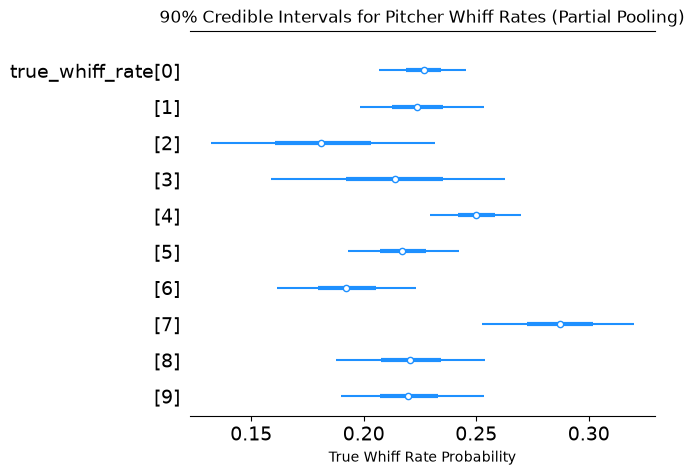

In [15]:
# -------------------------------------------------------------------------
# 3. MCMC SAMPLING & INFERENCE
# -------------------------------------------------------------------------
with hierarchical_whiff_model:
    # Run MCMC sampling with NUTS (No-U-Turn Sampler)
    trace = pm.sample(
        draws=1000, 
        tune=1000, 
        chains=4, 
        target_accept=0.95, 
        random_seed=42
    )

# -------------------------------------------------------------------------
# 4. POSTERIOR EXTRACTION & EVALUATION
# -------------------------------------------------------------------------
# Extract posterior summary for individual pitchers
summary = az.summary(trace, var_names=["true_whiff_rate"], hdi_prob=0.90)
summary['player_name'] = pitchers
summary['observed_rate'] = whiffs / swings
summary['swings'] = swings

# Sort pitchers by expected true whiff rate
top_pitchers = summary.sort_values(by="mean", ascending=False).head(10)

print("\n--- TOP 10 PITCHERS BY POSTERIOR EXPECTED WHIFF RATE ---")
print(top_pitchers[['player_name', 'swings', 'observed_rate', 'mean', 'hdi_5%', 'hdi_95%']])

# -------------------------------------------------------------------------
# 5. VISUALIZING UNCERTAINTY (Communication to Front Office)
# -------------------------------------------------------------------------
# Plot the posterior distributions for a subset of pitchers to show risk bounds
az.plot_forest(
    trace, 
    var_names=["true_whiff_rate"], 
    coords={"true_whiff_rate_dim_0": list(range(10))}, # First 10 pitchers
    combined=True, 
    hdi_prob=0.90,
    colors="dodgerblue"
)
plt.title("90% Credible Intervals for Pitcher Whiff Rates (Partial Pooling)")
plt.xlabel("True Whiff Rate Probability")
plt.show()

In any sample, a pitcher's observed_rate is composed of two parts:

$$\text{Observed Rate} = \text{True Latent Skill} + \text{Sampling Noise (Luck/Variance)}$$

To land in the top 10, a pitcher almost certainly benefited from positive sampling noise during that specific month. The Bayesian model recognizes this selection bias and asks:

"What is the most likely underlying skill that produced this high sample rate, given that most pitchers in the league hover around 25%?"

Because positive noise was likely involved in pushing them to the top, the posterior estimate adjusts their true skill estimate downward toward the league mean.

$$\text{Posterior Estimate} \approx w \cdot (\text{Observed Rate}) + (1 - w) \cdot (\text{League Mean})$$

Mason Miller faced 478 swings (a large sample). The model has strong likelihood evidence that he is genuinely elite, so it only pulls his estimate down by $2.8\%$.Connor Phillips faced only 165 swings (a much smaller sample). Because there is greater uncertainty, the model doesn't fully trust his $37.6\%$ sample rate and pulls him down by $4.8\%$ toward the $25\%$ league average.

"The model accounts for regression to the mean. It recognizes that extreme short-term performances usually contain positive sample noise. By combining his 338-swing sample with the league-wide distribution, $41.0\%$ represents his true expected baseline talent level."